# Análise do benchmark (10 seeds)

Lê os CSVs juntados pelo `eval_multi_seed` (`data/tripinfo_<label>_merged.csv` e `data/lanedata_<label>_merged.csv`) e compara as configurações. Todas rodam nas mesmas 10 seeds, então **a seed é a unidade de análise**: cada métrica vira um valor por seed, o IC usa a distribuição t com n − 1 graus de liberdade e as comparações são pareadas por seed.

Como gerar os dados: `docs/BENCHMARK.md`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Raiz do repositório: a primeira pasta acima da atual com um pyproject.toml.
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists()),
    Path.cwd(),
)
# Pasta com os *_merged.csv. Para uma rodada guardada: ROOT / 'data' / 'benchmark-2026-10-29'.
DATA_DIR = Path(os.environ.get('BENCHMARK_DATA', ROOT / 'data'))
# Pasta para salvar figuras e tabelas (None = não salva).
# OUT_DIR = Path(os.environ['BENCHMARK_OUT']) if 'BENCHMARK_OUT' in os.environ else None
OUT_DIR = Path(ROOT / 'file_results')

BASELINE = 'baseline'
CONFIDENCE = 0.95
ALPHA = 0.05
EV = 'emergency_emergency'
print(DATA_DIR)

/Users/alexandrecurylima/workspace/sumotraci-greenwave/data


## 1. Carregar e conferir

Toda configuração deve ter as mesmas seeds. A tabela de contagens mostra, por seed, quantas viagens civis terminaram, quantos VEs chegaram ao destino e quantos acidentes houve. O número de acidentes depende do tráfego, então muda entre configurações na mesma seed.

In [4]:
ORDER = ['baseline', 'greenwave_legacy', 'greenwave']
found = sorted(p.name[len('tripinfo_'):-len('_merged.csv')] for p in DATA_DIR.glob('tripinfo_*_merged.csv'))
LABELS = [l for l in ORDER if l in found] + [l for l in found if l not in ORDER]
assert LABELS, f'nenhum tripinfo_*_merged.csv em {DATA_DIR}'

trips = pd.concat([pd.read_csv(DATA_DIR / f'tripinfo_{l}_merged.csv') for l in LABELS], ignore_index=True)
lanes = pd.concat([pd.read_csv(DATA_DIR / f'lanedata_{l}_merged.csv') for l in LABELS], ignore_index=True)
for df in (trips, lanes):
    df['LABEL'] = pd.Categorical(df['LABEL'], LABELS, ordered=True)

seeds = {l: set(s) for l, s in trips.groupby('LABEL', observed=True)['seed'].unique().items()}
common = set.intersection(*seeds.values())
for label, s in seeds.items():
    extra = sorted(s - common)
    print(f'{label:24s} {len(s):2d} seeds' + (f'  fora das seeds comuns: {extra}' if extra else ''))

per_run = trips.groupby(['LABEL', 'seed'], observed=True)
counts = pd.DataFrame({
    'civis': per_run['vType'].agg(lambda s: (s != EV).sum()),
    'VEs': per_run['vType'].agg(lambda s: (s == EV).sum()),
    'acidentes': per_run['SAVEDS'].first() + per_run['UNSAVEDS'].first(),
})
counts.unstack('LABEL')

baseline                 10 seeds
greenwave_legacy         10 seeds
greenwave                10 seeds


civis                                 VEs                   \
LABEL      baseline greenwave_legacy greenwave baseline greenwave_legacy   
seed                                                                       
200496737      4779             4217      4037        3                7   
428956419      4800             4063      4018        3                5   
633816299      4732             4565      4598        5                7   
794161987      4760             4471      4245        5                6   
1145661099     4024             3051      3177        5                5   
1282538739     4617             4298      4416        3                7   
1329531353     4439             4347      3694        5                7   
1410143363     4692             3089      3835        4                7   
1835732737     4788             4500      4240        4                5   
1954324947     4800             3700      4472        5                6   

                     acidentes                             
LABEL      greenwave  baseline greenwave_legacy greenwave  
seed                                                       
200496737          7         4                8         8  
428956419          5         4                6         6  
633816299          7         6                8         8  
794161987          6         6                7         7  
1145661099         5         5                6         6  
1282538739         7         4                8         8  
1329531353         6         6                8         8  
1410143363         8         5                8         9  
1835732737         5         5                6         6  
1954324947         6         6                7         8

## 2. Métricas por seed

| Métrica | O que é | Melhor |
|---|---|---|
| `ev_duration` | Tempo médio de viagem dos VEs que chegaram (s) | menor |
| `ev_timeloss` | Tempo médio perdido pelos VEs em relação à viagem livre (s) | menor |
| `saved_rate` | Atendimentos salvos ÷ acidentes | maior |
| `ev_co2_g` | CO₂ médio por VE (g); só o VE tem o dispositivo de emissões | menor |
| `civ_duration` | Tempo médio de viagem dos civis (s) | menor |
| `civ_timeloss` | Tempo médio perdido pelos civis (s) | menor |
| `net_speed` | Velocidade média na rede, ponderada pelo tempo amostrado em cada faixa (m/s) | maior |
| `teleports` | Teleportes do SUMO, sinal de travamento | menor |
| `collisions` | Civis removidos por colisão | menor |

In [5]:
# nome: (título, unidade, melhor, formato)
METRICS = {
    'ev_duration': ('Tempo de viagem do VE', 's', 'menor', '{:.0f}'),
    'ev_timeloss': ('Tempo perdido do VE', 's', 'menor', '{:.0f}'),
    'saved_rate': ('Atendimentos salvos', 'fração', 'maior', '{:.2f}'),
    'ev_co2_g': ('CO₂ por VE', 'g', 'menor', '{:.0f}'),
    'civ_duration': ('Tempo de viagem dos civis', 's', 'menor', '{:.1f}'),
    'civ_timeloss': ('Tempo perdido dos civis', 's', 'menor', '{:.1f}'),
    'net_speed': ('Velocidade média na rede', 'm/s', 'maior', '{:.2f}'),
    'teleports': ('Teleportes', 'contagem', 'menor', '{:.1f}'),
    'collisions': ('Civis em colisões', 'contagem', 'menor', '{:.1f}'),
}

ev = trips[trips['vType'] == EV].groupby(['LABEL', 'seed'], observed=True)
civ = trips[trips['vType'] != EV].groupby(['LABEL', 'seed'], observed=True)
first = per_run[['SAVEDS', 'UNSAVEDS', 'COLLISIONS_INVOLVED']].first()
ln = lanes.assign(speed_x_time=lanes['speed'] * lanes['sampledSeconds']).groupby(['LABEL', 'seed'], observed=True)

per_seed = pd.DataFrame({
    'ev_duration': ev['duration'].mean(),
    'ev_timeloss': ev['timeLoss'].mean(),
    'saved_rate': first['SAVEDS'] / (first['SAVEDS'] + first['UNSAVEDS']),
    'ev_co2_g': ev['CO2_abs'].mean() / 1000,  # mg -> g
    'civ_duration': civ['duration'].mean(),
    'civ_timeloss': civ['timeLoss'].mean(),
    'net_speed': ln['speed_x_time'].sum() / ln['sampledSeconds'].sum(),
    'teleports': ln['teleported'].sum(),
    'collisions': first['COLLISIONS_INVOLVED'],
})
per_seed.round(2)

ev_duration  ev_timeloss  saved_rate  ev_co2_g  \
LABEL            seed                                                         
baseline         200496737       1593.67      1343.17        0.00   4072.65   
                 428956419       1764.33      1492.06        0.00   4624.75   
                 633816299        709.40       471.48        0.50   1756.47   
                 794161987       1455.20      1186.31        0.00   3769.86   
                 1145661099      1541.20      1189.14        0.20   3762.73   
                 1282538739      1578.00      1301.08        0.00   4195.99   
                 1329531353      1429.20      1197.29        0.00   3624.87   
                 1410143363      1437.25      1240.41        0.20   3729.88   
                 1835732737      1627.75      1332.56        0.00   4143.33   
                 1954324947      1112.80       844.42        0.33   2790.36   
greenwave_legacy 200496737        887.86       614.32        0.50   2256.58   
                 428956419        927.40       624.20        0.67   2406.47   
                 633816299        491.71       250.13        0.88   1206.57   
                 794161987        806.67       580.01        0.57   2043.83   
                 1145661099       811.80       543.56        0.67   2036.56   
                 1282538739       675.71       391.40        0.38   1672.09   
                 1329531353       749.43       524.24        0.50   1888.34   
                 1410143363       993.43       787.03        0.50   2510.96   
                 1835732737       826.00       553.49        0.50   2027.12   
                 1954324947      1043.33       814.24        0.29   2579.16   
greenwave        200496737        768.14       500.03        0.62   1958.14   
                 428956419        785.00       481.39        0.67   2067.80   
                 633816299        526.29       317.34        0.75   1355.55   
                 794161987       1100.67       876.12        0.14   2793.01   
                 1145661099       968.40       698.70        0.50   2470.46   
                 1282538739       652.57       365.53        0.38   1673.53   
                 1329531353       730.67       501.16        0.62   1804.56   
                 1410143363      1023.12       816.92        0.44   2628.15   
                 1835732737       627.00       369.47        0.50   1558.87   
                 1954324947       864.17       628.43        0.38   2203.19   

                             civ_duration  civ_timeloss  net_speed  teleports  \
LABEL            seed                                                           
baseline         200496737         693.49        542.72       2.21        128   
                 428956419         672.56        519.45       2.29         89   
                 633816299         595.40        452.62       2.50         72   
                 794161987         561.78        410.36       2.65         52   
                 1145661099        586.39        442.18       1.98        154   
                 1282538739        762.63        606.09       1.92        161   
                 1329531353        669.63        525.66       2.07        108   
                 1410143363        867.16        719.92       1.71        213   
                 1835732737        668.07        521.70       2.30        127   
                 1954324947        507.36        365.36       3.05         39   
greenwave_legacy 200496737         719.28        563.09       1.72        338   
                 428956419         725.85        589.67       1.49        392   
                 633816299         710.23        568.66       1.96        211   
                 794161987         544.91        412.66       2.58        115   
                 1145661099        486.13        351.05       1.83        207   
                 1282538739        837.65        677.64       1.51        360   
                 1329531353        846.94 

## 3. Média e IC de 95% por configuração

Cada célula é média ± meia-largura do IC sobre as seeds, com t de Student (n − 1 graus de liberdade). Com n = 10, t = 2,262; o z = 1,96 deixaria o intervalo 13% mais estreito.

In [6]:
def mean_ci(x):
    x = pd.Series(x).dropna()
    if len(x) < 2:
        return x.mean(), np.nan
    t = stats.t.ppf((1 + CONFIDENCE) / 2, len(x) - 1)
    return x.mean(), t * x.std(ddof=1) / np.sqrt(len(x))


rows = {}
for metric, (title, unit, _, fmt) in METRICS.items():
    cells = {}
    for label in LABELS:
        m, h = mean_ci(per_seed.loc[label, metric])
        cells[label] = f'{fmt.format(m)} ± {fmt.format(h)}'
    rows[f'{title} ({unit})'] = cells
summary = pd.DataFrame(rows).T[LABELS]
if OUT_DIR:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    summary.to_csv(OUT_DIR / 'resumo_ic95.csv')
summary

,baseline,greenwave_legacy,greenwave
Tempo de viagem do VE (s),1425 ± 218,821 ± 114,805 ± 132
Tempo perdido do VE (s),1160 ± 210,568 ± 119,556 ± 138
Atendimentos salvos (fração),0.12 ± 0.13,0.54 ± 0.12,0.50 ± 0.13
CO₂ por VE (g),3647 ± 585,2063 ± 296,2051 ± 339
Tempo de viagem dos civis (s),658.4 ± 74.4,677.5 ± 85.7,687.3 ± 96.8
Tempo perdido dos civis (s),510.6 ± 72.9,535.0 ± 80.6,546.0 ± 94.1
Velocidade média na rede (m/s),2.27 ± 0.28,1.79 ± 0.28,1.79 ± 0.24
Teleportes (contagem),114.3 ± 38.4,291.8 ± 80.0,302.7 ± 96.4
Civis em colisões (contagem),0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0


## 4. Comparações pareadas

Para cada par (A contra B) e cada métrica, a diferença é calculada seed a seed (A − B):

- **variação %**: diferença média ÷ média de B;
- **IC 95% da diferença**: t pareado; se não contém 0, a diferença é consistente entre seeds;
- **dz**: tamanho de efeito (diferença média ÷ desvio-padrão das diferenças);
- **vitórias**: em quantas seeds A foi melhor que B;
- **p (t)** e **p Holm**: t pareado, com correção de Holm entre as comparações de cada métrica;
- **p (Wilcoxon)**: teste de postos sinalizados, que não supõe normalidade; use-o quando   o Shapiro das diferenças der p < 0,05;
- **conclusão**: `melhor` ou `pior` quando p Holm < 0,05; senão, `sem diferença`. `sem variação` quando a métrica não muda em nenhuma seed (ex.: colisões sempre zero).

In [7]:
COMPARISONS = [(l, BASELINE) for l in LABELS if l != BASELINE]
if 'greenwave_legacy' in LABELS:
    COMPARISONS += [(l, 'greenwave_legacy') for l in LABELS if l not in (BASELINE, 'greenwave_legacy')]


def holm(pvalues):
    p = np.asarray(pvalues, dtype=float)
    adjusted = np.full_like(p, np.nan)
    valid = np.flatnonzero(~np.isnan(p))
    running = 0.0
    for rank, i in enumerate(valid[np.argsort(p[valid])]):
        running = max(running, (len(valid) - rank) * p[i])
        adjusted[i] = min(running, 1.0)
    return adjusted


def safe_p(test, d):
    try:
        return test(d).pvalue
    except ValueError:  # p.ex. todas as diferenças iguais a zero
        return np.nan


records = []
for metric, (title, unit, better, _) in METRICS.items():
    for a, b in COMPARISONS:
        d = (per_seed.loc[a, metric] - per_seed.loc[b, metric]).dropna()
        n, mean_b = len(d), per_seed.loc[b, metric].loc[d.index].mean()
        diff, half = mean_ci(d)
        sd = d.std(ddof=1)
        varies = n > 1 and sd > 0  # sem variação (ex.: tudo zero), não há teste a fazer
        records.append({
            'métrica': title, 'A': a, 'B': b, 'n': n,
            'média A': per_seed.loc[a, metric].loc[d.index].mean(), 'média B': mean_b,
            'diferença': diff, 'IC inf': diff - half, 'IC sup': diff + half,
            'variação %': 100 * diff / mean_b if mean_b else np.nan,
            'dz': diff / sd if sd > 0 else np.nan,
            'vitórias': f"{int(((d < 0) if better == 'menor' else (d > 0)).sum())}/{n}",
            'p (t)': stats.ttest_1samp(d, 0.0).pvalue if varies else np.nan,
            'p (Wilcoxon)': safe_p(stats.wilcoxon, d) if varies else np.nan,
            'Shapiro p': stats.shapiro(d).pvalue if varies and n > 2 else np.nan,
            '_better': better,
        })

comparisons = pd.DataFrame(records)
comparisons['p Holm'] = comparisons.groupby('métrica', sort=False)['p (t)'].transform(holm)


def verdict(row):
    if np.isnan(row['p (t)']):
        return 'sem variação' if row['diferença'] == 0 else 'sem teste'
    if not row['p Holm'] < ALPHA:
        return 'sem diferença'
    improved = row['diferença'] < 0 if row['_better'] == 'menor' else row['diferença'] > 0
    return 'melhor' if improved else 'pior'


comparisons['conclusão'] = comparisons.apply(verdict, axis=1)
comparisons = comparisons.drop(columns='_better')
if OUT_DIR:
    comparisons.to_csv(OUT_DIR / 'comparacoes_pareadas.csv', index=False)
comparisons.round({'média A': 2, 'média B': 2, 'diferença': 2, 'IC inf': 2, 'IC sup': 2,
                   'variação %': 1, 'dz': 2, 'p (t)': 4, 'p (Wilcoxon)': 4, 'Shapiro p': 3, 'p Holm': 4})

,métrica,A,B,n,média A,média B,diferença,IC inf,IC sup,variação %,dz,vitórias,p (t),p (Wilcoxon),Shapiro p,p Holm,conclusão
0,Tempo de viagem do VE,greenwave_legacy,baseline,10,821.33,1424.88,-603.55,-799.71,-407.38,-42.4,-2.20,10/10,0.0001,0.0020,0.112,0.0002,melhor
1,Tempo de viagem do VE,greenwave,baseline,10,804.60,1424.88,-620.28,-841.36,-399.19,-43.5,-2.01,10/10,0.0001,0.0020,0.325,0.0003,melhor
2,Tempo de viagem do VE,greenwave,greenwave_legacy,10,804.60,821.33,-16.73,-127.92,94.46,-2.0,-0.11,6/10,0.7414,0.7695,0.451,0.7414,sem diferença
3,Tempo perdido do VE,greenwave_legacy,baseline,10,568.26,1159.79,-591.53,-792.83,-390.24,-51.0,-2.10,10/10,0.0001,0.0020,0.251,0.0003,melhor
4,Tempo perdido do VE,greenwave,baseline,10,555.51,1159.79,-604.28,-837.27,-371.30,-52.1,-1.86,10/10,0.0002,0.0020,0.267,0.0005,melhor
5,Tempo perdido do VE,greenwave,greenwave_legacy,10,555.51,568.26,-12.75,-124.23,98.73,-2.2,-0.08,6/10,0.8017,0.7695,0.449,0.8017,sem diferença
6,Atendimentos salvos,greenwave_legacy,baseline,10,0.54,0.12,0.42,0.28,0.56,341.1,2.16,9/10,0.0001,0.0039,0.076,0.0002,melhor
7,Atendimentos salvos,greenwave,baseline,10,0.50,0.12,0.38,0.22,0.53,305.7,1.73,10/10,0.0004,0.0020,0.473,0.0008,melhor
8,Atendimentos salvos,greenwave,greenwave_legacy,10,0.50,0.54,-0.04,-0.16,0.08,-8.0,-0.26,3/10,0.4293,0.5625,0.096,0.4293,sem diferença
9,CO₂ por VE,greenwave_legacy,baseline,10,2062.77,3647.09,-1584.32,-2105.31,-1063.33,-43.4,-2.18,10/10,0.0001,0.0020,0.254,0.0002,melhor


## 5. Gráficos

**Seed a seed.** Cada linha cinza liga a mesma seed nas configurações; o ponto preto é a média, com o IC de 95%. Linhas que descem todas na mesma direção mostram um efeito consistente, mesmo quando as médias ficam próximas.

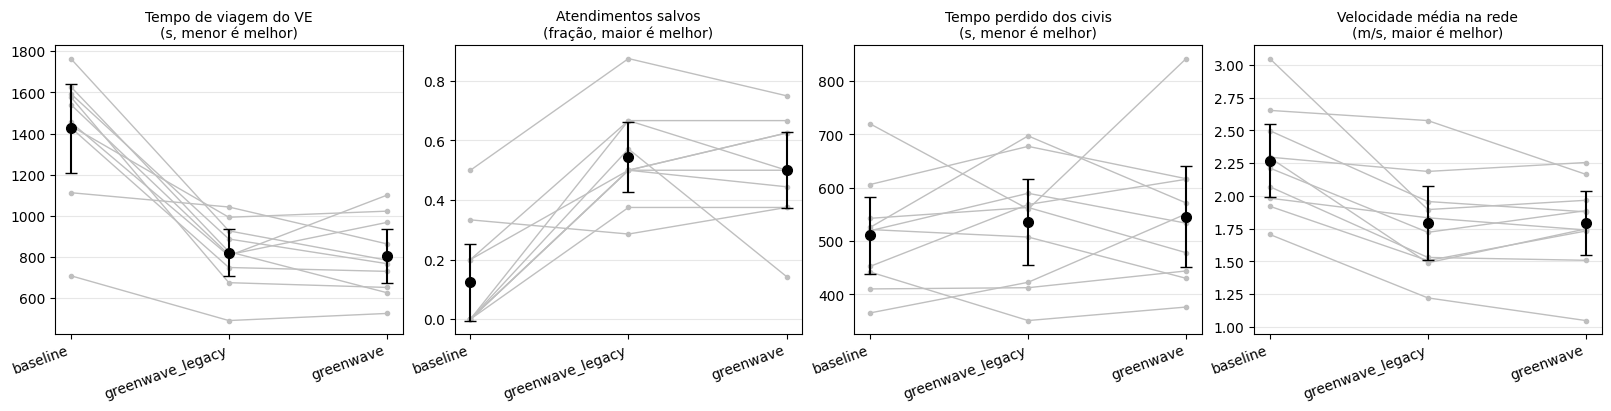

In [8]:
KEY = ['ev_duration', 'saved_rate', 'civ_timeloss', 'net_speed']
fig, axes = plt.subplots(1, len(KEY), figsize=(4 * len(KEY), 4), constrained_layout=True)
x = np.arange(len(LABELS))
for ax, metric in zip(axes, KEY):
    title, unit, better, _ = METRICS[metric]
    wide = per_seed[metric].unstack('LABEL')[LABELS]
    for _, row in wide.iterrows():
        ax.plot(x, row.values, color='0.75', linewidth=1, marker='o', markersize=3)
    stats_ = [mean_ci(wide[l]) for l in LABELS]
    ax.errorbar(x, [m for m, _ in stats_], yerr=[h for _, h in stats_], color='black',
                marker='o', markersize=7, capsize=4, linewidth=0, elinewidth=1.5, zorder=3)
    ax.set_xticks(x, LABELS, rotation=20, ha='right')
    ax.set_title(f'{title}\n({unit}, {better} é melhor)', fontsize=10)
    ax.grid(axis='y', alpha=0.3)
if OUT_DIR:
    fig.savefig(OUT_DIR / 'seed_a_seed.png', dpi=200)
    fig.savefig(OUT_DIR / 'seed_a_seed.pdf')
plt.show()

**Ganho em relação ao baseline.** Para ler todas as métricas na mesma direção, o eixo mostra a melhora: positiva quando a configuração é melhor que o baseline, seja por reduzir um tempo ou aumentar uma velocidade. A barra é o IC de 95% da diferença pareada, dividido pela média do baseline.

Ficam fora as frações (atendimentos salvos), porque a variação em % de uma base perto de zero explode; compare-as em pontos percentuais pela coluna `diferença` da seção 4. Ficam fora também as métricas sem variação.

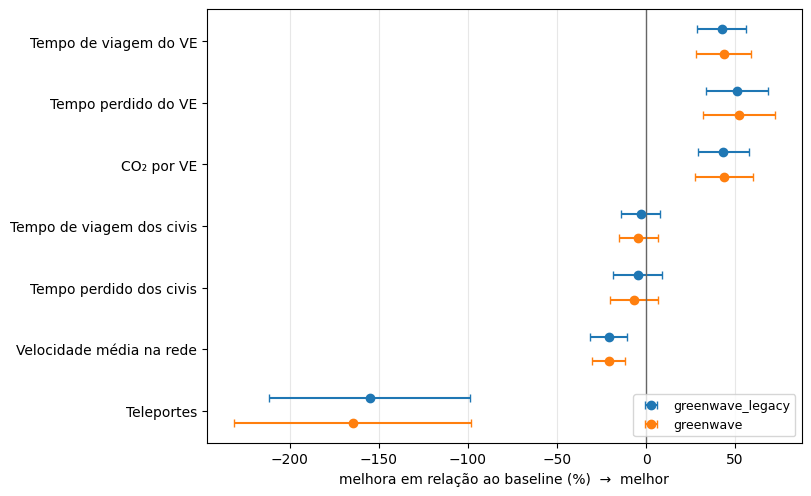

In [9]:
vs_base = comparisons[comparisons['B'] == BASELINE].copy()
sign = vs_base['métrica'].map({t: (-1 if b == 'menor' else 1) for t, _, b, _ in METRICS.values()})
vs_base['ganho %'] = sign * vs_base['variação %']
vs_base['erro %'] = 100 * (vs_base['IC sup'] - vs_base['diferença']) / vs_base['média B'].abs()

titles = [t for m, (t, unit, _, _) in METRICS.items() if unit != 'fração' and per_seed[m].nunique() > 1]
others = [l for l in LABELS if l != BASELINE]
height = 0.8 / max(len(others), 1)
fig, ax = plt.subplots(figsize=(8, 0.55 * len(titles) + 1), constrained_layout=True)
for k, label in enumerate(others):
    sub = vs_base[vs_base['A'] == label].set_index('métrica').reindex(titles)
    y = np.arange(len(titles)) + (k - (len(others) - 1) / 2) * height
    ax.errorbar(sub['ganho %'], y, xerr=sub['erro %'], fmt='o', capsize=3, label=label,
                color=plt.cm.tab10(k))
ax.axvline(0, color='0.4', linewidth=1)
ax.set_yticks(np.arange(len(titles)), titles)
ax.invert_yaxis()
ax.set_xlabel('melhora em relação ao baseline (%)  →  melhor')
ax.grid(axis='x', alpha=0.3)
ax.legend(loc='lower right', fontsize=9)
if OUT_DIR:
    fig.savefig(OUT_DIR / 'ganho_vs_baseline.png', dpi=200)
    fig.savefig(OUT_DIR / 'ganho_vs_baseline.pdf')
plt.show()

## 6. Notas de método

- **Unidade de análise.** Viagens de uma mesma seed não são independentes (compartilham tráfego e acidentes), então as métricas são agregadas por seed antes de qualquer IC ou teste.
- **Pareamento.** Com as mesmas seeds em todas as configurações, a variação entre seeds se cancela na diferença; o teste pareado é mais sensível que comparar dois ICs.
- **Atendimentos salvos.** O número de acidentes muda entre configurações na mesma seed, por isso a métrica é a fração salva, não a contagem.
- **VEs que não chegaram.** As métricas de VE cobrem só os VEs que chegaram ao destino; a tabela de contagens (seção 1) mostra quantos são por seed.
- **Muitas comparações.** O Holm controla o erro entre as comparações de uma métrica; olhar nove métricas ainda pede cautela com um p isolado perto de 0,05.